# Практика 6. Как предсказать недостающий факт в графе знаний?

У Китая в историческом наборе **Nations** есть связи типа `embassy` с несколькими странами. Часть этих записей скрыта. По остальному графу обучим **DistMult** и спросим: **с какой ещё страной у Китая могла быть такая связь?** Сначала получим прогноз. Затем откроем отложенные записи и проверим его.

Запустите ячейки сверху вниз. Данные встроены, достаточно CPU. Имена стран оставлены как в Nations: например, `ussr` означает СССР. Мы восстанавливаем записи исторического графа.

In [1]:
#@title Встроенные данные (выполните без изменений)
# Встроенная копия исходных таблиц. Выполните ячейку без изменений.
import base64, gzip, io
payload = {}
payload['train'] = (
    'H4sIAAAAAAACE5Vd23bbSA58dr5m43wR42gyXNpSjmhnJ/v1K7FvVYVCy/syJ2NJZF/QuBQK6PPp/e/T9XU5/9if3tbX9X25/lle'
    'X9fl/HJ6+ti+nH7++fX+tJ7fT9efl9+X68/929PHvnz59+X6Yzk/XU+v3y+X7f26nPfX5X29nPfj41+X+yOf3te3077eHvWf5Xr7'
    '+3798rE9nU8/b9/8ffp++nv5vV7qB/UXtwfiy+5DuD3v6T+n9eff76cfH+ffl/fTbTw/1uXLy9/reXlaXl5u37i/uv759oqPs/zg'
    'mEZ7x+nt+7Lvf24D6XNv83m5vL1dzt9fLy9fy7BePr4vYVC391zOt4kt8WfPT+t+XU6v91HEVSufyVuOEZ9/XsrXvl+X/66vX/or'
    '6Mv30Rzr4aYA/346/fPrcn2/v7Ws3+nlcr68rS/L+qMNsOys3b0yBl3026PqB7f1qC+4//FYdS8J5eW0djjiY41+nH6dbv+5y9sx'
    'vTKu2+Per6fbc07707HPdbej8JR33NbvqWzv/akycnxnGa0uN64dLvjY6ftL7n/bfl329T69+8j/qSJX97XtSh1I2O3nKodliu3b'
    'dQginMdafP+4vi32TGy0CTss2/7+cVvNsjV1v/TXiXAdyzw+6zJUP+A5xjUNgnqcHZx9XZd6btfbME9vf1DiZAHr6Tqd3tafN7mi'
    'mfKcyiG6/PXX+rIur7/X2xbtfRv6jEgdyQTqVz7O94csr8vLO50FPf+HROzXYxfgbLUZ3mfOx7/sfFvEfjxvb/Cy969x2O+yXX9+'
    'LHSii8YkVGBwqkWkZKXKDutZRWW0kqIt328S+8+v0+uP9dfr5W1RYbwPnQSuS+d45flyvp3k19tfM4tQH/7yR85jUAZtYxbWK5mW'
    'tFalma7Lx3Xd38pQqhDcZyP6q32tKlV8+jH3rt27XagbiiZMhKjsNT4qUa5lX7pU3+z2H1q6rkuOtS6bYqzvIgqpbc1+NSasjJgN'
    '+zZb1XokyivUpJTloc1qWvz+ep4angFUNrglx8nr2v02sqpD3GGsH9Fc6i7RWRridyxumQkPjU5YERb+wnGYUe+e/zpd7/Pdh9eC'
    'cypjM0cS31RGQs4HnQ8UqvZAMBx3kdpZMeEQWJfFHao/iV5Cdwjq6RdXiI/QbZjtDOHfqwSjPqzCIodlHPkmvrwG3Yso82xKOz9O'
    'uJx10arrAVJV5z7mWG3d2NUx2mCpju+20ZZhlTd0B/xl+GJDZmaOdtM19X+Dqibpeg47gPJQFjSKVl2LtkhjpmTV3bqKJgPXERRo'
    '8babOpzIS9m/sKjWtb4HHPcffL/8ebm8v9/X/Er7Nb582EV/dsnHUxvQBXUsCLuxbK17cBBCFNEQ5CJEse/64TY7jIDK80X/i60Z'
    '5qfOKdcwh9zIzI6lM64w+maptkh+Z8Os6n1UNd0M133TnLlVJ5c/gwENTRj3v4kXqPwSX+SWKDcEFJA1Z/94zTHdGG7f5bWuUz0W'
    '3zIvvmozI0fTAPL+tMMBzOznsQBd06meoHUsQ6iDC1LSjGs93rhizSzsi8Zaq3U7graqazk2UpagftCjpyHw1dFpZwt9Ddmh47DE'
    '6LT8nczS5rVGnWF7/fD+5CTX/dIHf4XpiTqiR2G4Nzzm4KmWL4u3qu98bipziXOp+xl1zbF4uP1lAVH4uw0umzCwI1iZOnanH8pC'
    'Sshi3kJDRu+FHdvhzAMw008LqRlGuu6j5bAcAhNYDPogHK62Byh7dLTrB+2cskthcKr+IJHXYy/H6E0Em3i5A0dBkYHzM7UXMoYR'
    'JnIUX6Oi5pV9zurzYIKP+JUOr5UHDoL6JtdHufBkd2rAAivNjvHy0Fnz2GeGAIyN+PXrehvQPkANUlnj6N+XlIJ2wjOGZwwBLUg0'
    'CdsmsRRjMrAZ3RQ5ryngf8Xr87PsRg9UXJ9jd+ZmgsJW5xuI11T8x0uaiAezOgLD1SJyKYJYflcWmB2y8iwC/IpNFFOqHnoPVZy3'
    'hFhyqpRIEfZzWX3NopCiB+fByPbaPYQ0h+ZlDDHz176hEpPAWVBJiccXZ1J7RB3Opwkrad2aq1zd0W64QPU6T1ACxMwJDKoxh+xg'
    'Pci2lsFGjLz4jk04h1Ow+3wIRgTBDwVHJ0HYRvg7BuD91Ag9WoRxaJU+9K5WQKdFSQZZE+0VT3fNI9S9HdZnuE203zYmSdHzoZ/M'
    'fpG2BnjNmd3oCEJoEo+2LuixecMa1G+3AzHCih3cmJFHGNgheoV6Bg1iiz4/LkCG2d3NS5hojSiid1XFmGxB89AJoOw+d4Zo8Omt'
    'LnadstjtoQkMwlojGT0esLeQkYreZf/BDIlpkUESbzc7X86ixxNMdAYY5gTsD+uaqyqI2/r5IRAXVEQNmdtfpvGl+DEeVjYIRpOC'
    'AEUJwkISVs6YSS3pECUMKZOPMXVLdlu8o0uvClZMnIORGcnXhvaVh/z4uJaATJNJbG62HC0ZJtCI333S/RVdEzBC1Q9EjAMFJLlj'
    '7B2S1ED+gOqyHGuHrywOCuhcd2IQsK2aOfhluCZkNe3JWeJzaOwCM7bv22ybTxP0pbHQPXmB7enBfoPvQCB89z4tSBizTnahawAl'
    '+IKJe2KCeHl/X142A9NvNgCWhPOgY3A4FhzLjihvWfRrsjVImKh/MpJYXsaIgM8jG4qHSEHTEMGLi3hWR2UM7F72A2AZSRpM8NYJ'
    'S2KSz6N8UaaWrUV1qcmqJOD0VsIKBCVbprQfLf0zI4HBCsphfh7HzwABVjMH9zXLzRszFQCOkOyKUGhd3sn2oNl3eRIB3yi1gahI'
    'XTnO5O+LdbtKlLo5eLgjN+oZIKZRDHOPKdSYe3gV8vLOcZOkUxt+nw9xCgYi4vJX/TfIt5EE0r9YHR6LNCZIeBW9fGTVqvRmwbVb'
    'l4IpNM01pK3raPKKPUieABoYK4dwxoDjZTuOAWUuT9cJUUg2kwhIdn2xDmo1aVW4yZBHk+HVhnWGDcSY5ITF9zLJnYWFPtrbgLlb'
    'DF0BtK8R1ku5eIrsmERm+/QdDK4xc+vUfAjCBx4vszVJXkkldW/PcX9yGAnDzSmgTNj20Gtje2DMxm20bJbPyFUfYP20xtEt419d'
    'Q0lc1WnH5D54vpOxdJNLOJ+DqgOXokIPW4bW3bPPyOPLXPgq/Ybehn46Qj4+9Wce7dBGE6JrPoehWOFtkQ6w+JnShGycYLlWyHhp'
    '46wPkZ11CnOMCd9oHFq0uYID2/C7SDSc/sDbsGAoaiVKSey5RQ/x2WSho1Wd8s0NHMpUaFmBOSzt0mSGA0hG4HiFl5aI2taJ91gz'
    'JEUa94FPCEKYhJJ0Jw2znhAOhuXtMBynBwaBxYLxfV+RytPYsPVPTIJx5sjECATV1Wgg8WVJ2XKkCHipYR8L1VixFWJ+dP9ScPvg'
    'ESIMFOgjWzCguq3jANjwItJ51NGDUaFeqL5KfV1HcRgAIHpCFN62t2gaF6EawP7bLMam2V/nCisYD8LltoeIzzfZJ9XlkTdIAETn'
    'VanZITyjRJ11gZfIlPYHLCRXO0Dvk3EG447QM6ObSm9YF2+Oxi8cPsEpSgCibO2CV3vlVHzKV4rwoQMq2LaQWRqPGqho1zTGcjQP'
    'VywvGgSnMyPeS4x4XvsEKaEoRxLDfXK+PEfzNlggI3zXohNCNNJwkQhyaqrIZPCEcDwG7DwEDE9jFgYo1z69jNGAwqiDuPDpNDMm'
    '3tmASkyV1lsM8u9QiLyaTvHch5oxBDCFLOEArlkWVguljZOcyLwK1A+f2wnYhNPViO1TqhLynapP5D1BtKOgJSRt53JvfcpsaNBV'
    'GtlBK9sOb/BqSgOWQOGyBWfigGianoK+obQnAaJUV47JBlqaQumbzcXDbAKBvD6ha1VCQbhWxp5j9kR07s7XJBYa5aVaTBqz9REs'
    'kqx5CPaC0cuK7sxw9hQyN3iRD9NHgjjmXCfhtKIIqTOwejpNbhAXTBtFMRa7/yBbNEC/zPVYuawCTytxRY0HYHK1D6s1gx5O04ke'
    'jwV7DlmmmC9gsmFw8pSegzhUUgdNIeRjgld/lTpINtBpuWq7g4lxAC/YSItxjw0d2RY0cNkSREZMIo7MFxKYlN++PSCaLln978b6'
    'lip5CXdSAxuVjiRikwjXF5JrgodJMoSkQvYgIaokCA25pgGzA+5ogo9kVbAOlcz84sio2BwaPwN8gSMVHOCQuAuUspjCwcpTYcXm'
    'HufAlme/SYPVqnaNU5OHa6YbATkXmG4zFnOrgMLQ3tYP6ynbEZZuj0uTR5QeqzanNgI0gfoDiIApDuuOXechuVp2qSRkrjQ0xGBq'
    'DddWEbyiyj7WXiIizL+NUCXSOFKC2pbQi4qaZ+QrcKMBLsxrG1vcLFmpNovmHQakJSa9UFhBYU0waoSYie23Gw8fR/IJCFErMMEq'
    'Oeol1yOwrwm0duOB8VRcscqDIkNOqWbEG5JLoJGASieHMGUZRh/HEKhi9BXzZxDPW7YfFdYaN1PRysTl9xTDTerRHqhgz2JsrxDM'
    'SF2HkNnX7iDGOyfWd16uSzktJPymJUm2NGPzrRea0gXbh0bE0GtsEvuAdowF8E06pECZcUXTSAcRHCOJEbQboalSszjwRtIYo/uO'
    '+RKKYsSrbrYjcb+OWcxRjikhhRBlF0SapEOSnZ3UKVAvDnuwhJqaEu9K6J4rG0OJImTS5P8FBZJUyWB+MlZk0PtATm6/7Zz5GeV4'
    'txzEb7HKAzA0p/GYPxdTpxnpaVRm84PIlgLlkPW0oND4mkwP8ZY/BNKivlUnU4Ko41CaBJnk86V6Lta4KtOj0f5c7GgzFf28kSNH'
    'e8o4vGXHjDOhEC9o6XDWCUfw3qqJ/CFOISxFSAMMR3IV8OIZ9B4OTeIu2ZdIyopphyxXAtCQKFi7D9S3KXCFE2yIQXzjtVaQkqsZ'
    'upY2zO9QiIJp8lCulq8nMW79hzZBoiihVvpk6KL4zAK8SJopJBbQPZ/wVHsGwbB2SRicAaxHKXgo5O6i9+Zr3IxrFDB6U+CWIYaa'
    'dVXGdji4zgG2zDKaXiyy8Z3pXOEpT08NoGNksCdmqkgnybZIkgqZotTtQLmehCVHYh7OEtahaSmh9kHsOOIngE+H+AsYS/V7iWed'
    'gV6faEb3aLUhLe18Jq1zyGIK24NN+l3MerlkDkqSc+KeayZKIe8cAIIMBAzx9wjTvzGVJJDFJE7LeeSmfRADxa4MLuOKq1lxvYye'
    'fek+wEdJ6X2KK2p/p68DX8qh4NPUa8ySYWoEOy5wixBvY/oJw3Xlxt2bKYYT3Jk9yY46XSV0xlhItSSRhPNFIgZpNjTgElxRXfzX'
    'gldhDxcyYUZJpq0joUtkEZ/Xy37zSK7X9f1y/TMFwmxvHG5yOWtAOpbR4VSbaTMDySPDUnSw5f5pwLtLTPBfYgyilGilqEtlIcJ0'
    'D/v/2QqApJi1BWYKP0bxd462Qb43n/Xglj2yHy7fg+cpaUUTxoyZSoNVB9JqMAht/3pvzIHuGi4d6tgkmVRxlkkpnEWYsuT6FC7B'
    'GJApk7POozFiYpTed/o0LXZHiPOwqaiDpasMPOx+ksT8SfrHw3ib736qvE5A+GxWY1PDb2B9Q0VKIs1egpDVYXEbuk80381I4Q4f'
    'f3a5Qe2KI/3whq3sgIc9BB5haO3t2juy9rbjEQZCSIodNsN4Bz/GNSLGENMLBfkBvgnGNPFLzIgAFUWeke9bu5G2lhqvyNNOcQ0g'
    'HtsS6Ly1ui2EQyuqepk1Q8yfmsQmczz8iw6tqz2zlaAK6j+cDcdl25L2maKYBR0UrlGv+DFweV6mDMlN29k20Ks3RznBpIxpBJzV'
    'C7M9l24SpjE+JPKVOL5NElrOQ03L7rr/FVkohm+oYUrsY2N1AtUuTstsmRQAlMXQNksgZFsRB8VKxzNtk0GIuLQVFgg4z9vtq6Gv'
    'CB8ZA4EE73MGQsLN+h7fXzRBy/uRiwQG26EigQ6lT5P0OmSPP2kQ59M8nbdiGnDu6YHq9XZSCZfQ+1wWA6h5tkjQphmQzAaaVsPT'
    'ngIx+Sgi2AZ4GdUBYbqOnjLeoBrT5i0rSJ3nhm1ha9K9NUlX9r52bmadegLWEYIyWhlq5GVwk04W9kbUqtWkz2YHSMR+YvWFbXJJ'
    'eFTWhX8LNYyBIBVqgwYBxQJjz3m7uIf9k2HpQ58I54BPeP3d0afA2qbjpREEGoKq871QmvMTW2/FnxL4mBF9wcxsvrWudhYCNMXg'
    '5Ylej1zrrAWvFrq5FNfmGk5/MlM5ps7UtX3J7mcxoWoWQdbFZmwKy7VFr7pWu7y+1jU+5puNwYBJPj3NCX8h9HajTRkiLkfSHg7R'
    'E8SUvQlcJy2YXGdC186dju70vh/m9muTiW7nuD6FXBbTUBUrQhLUIEL5FgtOr3fSPGeWl1BzLLFumhqZ1WyEPk87IRZ5SRjI/PxT'
    'G2X6ziCzpK53q2w8mhD+0cwZokheWz5D9TdXgeNPrzZ33B83htuk3RHxjyL9wFEhsKv6pBqTEr9Z9ZojPqDHHMqJE1ATbhIKbBhM'
    'PzGlISNvCeyRd8uM/RMn1zUIdV/tVKgtdFWfIbx8cEOMUaDZ9QgWktQK9DNQOdzo5+VPm3CktLbX3WrGwBbxgRG7TyCOrOglFGgI'
    'YCJqOTdZ9mYq9NJcM2ZPHv0qXITEs5t1NOpVf0zNhT+YulvTpsV3cTfGz3cEDtzf56ROIDCCXR/djtKpt5ymL/0lnaOOW8zDMrcO'
    '4f6RpBHNrJkqqhBzPwWnRSYKBdGX+HJtokGHBjwwo5BYVT1unRRyZdHTMY1q5lfkPG4qjXeJSg/rCNM9CkkkKZqhxk6jR8jFlfq5'
    'SuK8P3OWXnF4fUixGFvhRNSQnweDA6t69ljeR1CNbQ3HxCrx9NME2ogpqbtzuJ8KyJtJEQT+Xi5JWGKxZPAuNrtxcWP1eOW9kuD4'
    'TSo7bBPw/FLR0LpRb5vcHhVxNK8oegKHekmRw8F+imlXR8AHZrFqqhRP25TSl9yAq804OYwP5JURPHyiK8GjG6uYUOwKIjNIMLt8'
    'IKuMiiSa/6tUd3jFs8ufhUIk9EEM7W2/Xpvp1LbASXPt5KKu7hAGuMUpVduChVKqtmFNGocSLLmffp+u7XCtLwTeSlFB5BYkd7li'
    'KuxzpdVKDfZ3MKSQniSKBXTOWuNuE6vtkI1541bCo20Kig0SHAlt2rfN4mffzpb4E59JoDKzIFKx41oirs41dYZGNMwS50dm9HDb'
    '+Yy7iAggZzvocIeFb9GVnrV9RWQvJ/xojJHU2lmeuedGBxJ6lrjOOm0q35T7DJreZ7OQpC4hsDU51TmjMjtA0vVhzCo2lI6SU/mc'
    'y0HtRPpxSgluAX6JhOVQqxF7itOReHy9/LpYXnTWJC82SWKCnIkuwLtWFzD6K+6CetLU9m4VKTMOl8WPBuFBR5o7jAk6tSb+brXj'
    'rePafY3CF98eJWzfRCUhg9YX+q7e+Kb+USxXfDCEbvk8GGKu5q6ehHV93a2Koc5OkmW+6866ZC0aXUeWZ9r6CXCW3z3njK0hk5Ln'
    '99nm+1+RVZIX1jhfWS5fylpXemwuXtrMrQzSS+aeh9IXsNAwlS3BkRrLer7H4trThr5/2lkDiw3yLBeiNdwX08Sjjo0buUOf6cUd'
    'dam2lrDXnPiCMds0zGrreU7PQvQuIQzFH9JOOF4moVfDCp5pyNRJg31kX1r+MVAqzHW4IKGmOFHqtQqyIYSKcJ1kj8oeo3jR77HX'
    'xrRcN7x5s3Fsz7c48qyhlWvqwVSmxpL3Nevw7nqZ5QcxXv0BRXGsNJS7jmdYaZoahBNkmxrJ5DqyyNvxAMzmsKRw7fWA+ixvK+8s'
    'zcknAAjT02nLtdbF5Gq8Ym/h0aSoqKNhTcGhCTWiBNe0ss8cIA9KZ5Mj4oJ2JOK3iCBBxKQvk+6tM4xa6TxpPGXakCgONgiGKfnL'
    'oDJMUp0A7NMiTqHGeCrrxvp0y+6eBbM4nvSgfUZtis0XtxkPkXw0aQrLl7xNmriImRcgy7tRU2WZ3FnTlyi5/9qcNXNCvG8gS2VZ'
    'YYkuwbqwLIDeXXfrcUonkj4T3lmbLNw5IU7MJHWLzmFoSvYAVvYVyJLUlEyWtFfT2yc9aW5SnB6pLKGQSBtzUjeA+9lIb2LXe+wD'
    'lBibVWxJ6aXmhdIWgYKBGVLHvB/AxKI+gGxAkWaImCnZjAc1RimhwjrWGESoaHMRJc8u9Ooyvb5Dp3m9AGjjK2e7xXLXRPoLa7ac'
    'Iw2HEbVHjELhPgQuvham4chOxAtKNFQ0lOctsWn9SKZQ4+JxWGPXZdmHVHmsmNKxAN1Pr5nk455GteSbkLj4xNO4n0Fhp0GAi0Vp'
    'cptUCldSDsbdIsuMiVkjr071N6XErlUrIpByJYpDJTd3z+vAFyWPLfc5J4fblgCap7mEoyasQlCkpNYa1KM8JRdIJFk+qJKRFU2u'
    'LbQTDxd0yw1BzspBDsoxVV1xbMNdA6viYb8uIblKaZWJLgJ008lYkVYhSe+if2nXWNfF7FuRrP8BZWho+r2YAAA='
)
payload['valid'] = (
    'H4sIAAAAAAACE31YUXbjIAz8dk6zuz0RcWjC2oY8sNNmT7+ABEgg96evD9sgjTSjIfNxVdNuNh2MnbVa1/dk7M2oy9Wrf2advF53'
    'r9VudJj0/f3cL/nvpL+fzu/hYzqWi9X7Q/tV2VuY7N2lpflhrMofu8ObsE1HCP5yLHHzXfu7ezl/D5MJXun1kp6ld/XsrNvMrMxt'
    'mmNc8EBvVxVCDsvZGKa6wGfTy7hV213Nu3E2TH+dvymbzjjslzb3x65vh325XcfD40cpK3b8xwQ5XtJZ0+y2zdnr6ubfZf3pUk7j'
    'dhg2hsEyojuWwCMcMSgA7OrcEkFqgDHw0unL0wWTMooB62/AIW8nPIw7Y4y0THEVQxtgiDWg55UIYRMsGq0CVDyXoW6f34prCcyb'
    'fur4J3ZO2SOtNyh/QfwYzgAkxaE2ATQWyWIzq9mVf8fmNCod1cpJIGaQt17Jy+7z08xGrS8T0QssK9b5qVJptXu/wJO2svoeYXjp'
    'lGMOpMR9M8/VbWp+l/YAniQ+YFOUNzkFMtkAebE5M2cIznSZ7JNri83QJXVW9RQ9HGydRTJd9UPFfz18VVkshIz6QGkzMFSg4fXw'
    'm0qoQJIFcca+9AqLmB2P1YCNWi4xXFjiKNIWq/G1lkLtgJ4edAAyjVBHSnxqn/APOQvQGvZuWkb8axeivC29VJH2BPz7puLdDf2K'
    'gJ+RrgptEd+mByi9Z+pSK0lyXHi317ZokdP69A2nSlE5ajGGWniEduQgLRgUtKH8p0AKD4TGxODY4ECQCjm4jrE0AMIPBBxglBsc'
    'ngmIDpLG6oUz6rS3MyUT8OWbnbCUiQyQJBVeCAIzhi76CaV+9FelIhTFtQp5i6EwcXQKLWg6BOOuz6ePShCaqKJS1DC+lC/wJxzk'
    'yQtb3w6vUs5MQzsqFdNBaiArwtDp+dv2vGsbEHehIm0ekyfMTvT14E+zf8pHAzBNKZvs8GkDyXfTz4i0JnIhi3oLMRmV3SsbVgWa'
    'RQeM+BwlQ/AJRZrK3FV0KgKSXLQZy4WZXs1lOat/Vr6h7oOOPcSmqREd2SIlgEtUiiAbLEls28i9e9kIV9l06oZDm+O0QtQqiHaA'
    'Ssfgp7C+9XRzjxXasXla7Qj6iA3xXUzAlknNc/w40yxngXsPnuzUUzUjj1eDqkq1evRI4mfpzUE2FHBoI+m544ZmbG/27Q+DkPVb'
    '/cR0qgIPSjnJPUioWj+vEgaNBhUB5mlO2DUShe/ejdZMRiZ8zVFjIMOsAvE59+s4xPmuvb2k7r8IcDww7EeaZ9UJ0GtG9VmMt+P0'
    'J4NBkDVhQqGvQ3dNoiY7SWIMWwnZQxGoJ4ALGjgu1vhMH0YoF9KNY45tGvxkY2WdVq35kfood6OS0heJI+M9XFkm8AZ7eaGElWM9'
    'bLpVqTV64HHa1Etf30zCYefGk0/S6ubgblDcs8BOqXqcG+ynDDa4zt1VN73oUUxOurtq77vKrXEg7EJGLbHx3VhslzFd50Fz6Mxd'
    'EP4ho7ofdtqrbX7WxFLsgjGBtpHvW/AbwlDgvvfbjUb4mWr0sBg7Xr8Z0hDqf1eoFdfzEgAA'
)
payload['test'] = (
    'H4sIAAAAAAACE31YUZbjKAz8dk6zOzkRceg0awf8wM5M9vSDkAwSKP0z854drFJJVRK9hdX4++QfIcRHuk5HSvHi/N2Zyfndxkd4'
    'wYvJpWjsesH/pjk8n8Hf1jD/O83HzVyOBL+/283mf/xsp/nbeXO5HfFppmjXu9vW8DTzGwMcy7RtMew27amGDN6mHPbpVreb+Dbz'
    '7oLPr5fLhiB/W/f43u398K98dPJ2/7YR3qRLCScQX6eSRYMg0sl4z1xq6rdo/nerlrx9vLf9wuLBIfo+oJ9uISx7ND6thkAn5KQm'
    's67OAC8cNEbiXGKiF6BUsoYI4IsdCVSXcqJmcj4spNjnzaT0ngoRIonzDSZSQtRnmXWEl2HYP1uIY6HMPGdAkC/8Go+Hry83O7O+'
    'XHLnCeRVMlqaBvGxANRKmdC+XlQbIKBmyan8L8S78XBsjzZjsmmqQBnklwur9fvYWl2LYvEO/4HsE7cGsfZbBYJSwD7JVV62kLnJ'
    '8UEvfwDDWG48gpQyaZr6U1ESvcUJ7Emn2qKabJgD8CyQFD0HbC1dpTm/ckxxhxMaiIk6v8bVqEW03j4yopcF3VQNmr7zWvULZSJ6'
    'SWWZ9nBEl55XEhdKiD5+s98mN0uULcLIAI7QPxRieU16DWMSH9EqEkdVLOpjKXGMQLhkVclActbumQNlGrIlvVtPdT2wMEVJYYyu'
    'sDCBKQlLXymoCWGF8tvECeMBQuoICLbV6USVFpHgcfkekn1WeAdI3Oe6HlZcWeQrWo/6MsOSDFFLavZRByLz0nyedfnZ+JJZJIq3'
    'WRMFJS29nIK3AfKrt+hcoxrl9Fcin7EsnyDRjQ54xu23Vwg1XY2p+jOcZPMCgYwjv9ajelNL7h+OAlhC+QpZsYlGeqqkSq514zu7'
    'W2oEhUbG23ppobYblo42dYCN4GnoVMKY+XWBygtivvssG/N9i/YFSPsBKkhnQn1dyDMXLU1MqRtdQkunaYLsNaM5izQ6TR0rYnss'
    'EUpewg4A+wdJds0j5gFxu4yzu/nLHPyXjTAJuPHyJDlAlNqHcML7uA7xFDbfD2xWVyxvhLn9cKqrJNZMYMYaSOcVnqFtCkR3N5rY'
    'cBxRUYJjoZUw1y6O2GsGX4eHtDgyGy0wOoB00xiXzGv1e1EzIocTuoa053PR7SG+fx7GJbtuMVO+ONw3lv4Qd0d8xSvYBhLvKo4s'
    'u8dJDP+U1l0Fsy7i/g2326olWV8+1YdhIEs8roJtXg7XsY4+XC9guWJe299wlCsKa3G+8i29GLXrgVhS0JMEU9APimlqS0BbTOWB'
    'n8r+i05xJqRQRWdqlwlAOVyr+LZa3aDN0u5R3VzLMsBvPJ3w0FBIeLx5aVUbp4NykRbLy1kkUboelvJByEJ39dNCkIkr27MUv8QQ'
    'Kq3D9bgRLesrriryhpyVpClW+XsDMtvtOf0CzBPg32vdyEWhrBvanRqUplzXxe1M7BdKwT7tUW0zuB8RWdFEKHe1ZVy9BXnaClJm'
    'R6llrXv3tyChU0IgN162F38iup9j/N1fH2DU2VcTAAA='
)
def read_table(key):
    return io.BytesIO(gzip.decompress(base64.b64decode(payload[key])))

## 1. Какие рёбра видит модель?

Строка `china  embassy  india` задаёт направленное ребро **Китай → Индия** с меткой `embassy` («посольство»). У двух стран могут быть и другие типы связей. Покажем на рисунке все исходящие рёбра Китая **одного** типа из обучающей части. Вопросительный знак обозначает страну, которую мы ищем.

В обучении строк: 1592. Стран: 14. Типов отношений: 55.


,head,relation,tail
0,netherlands,militaryalliance,uk
1,egypt,intergovorgs3,usa
2,jordan,relbooktranslations,usa
3,poland,timesincewar,ussr


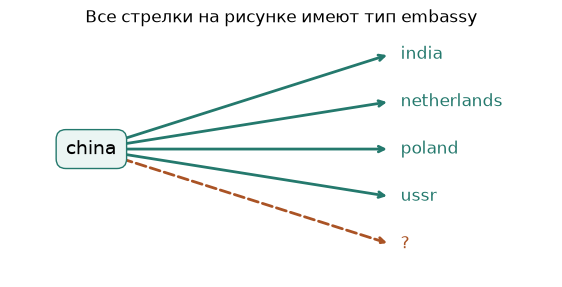

In [2]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from IPython.display import display

torch.set_num_threads(1)
torch.manual_seed(11)
columns = ['head', 'relation', 'tail']
train = pd.read_csv(read_table('train'), sep='\t', names=columns)
entities = sorted(set(train['head']) | set(train['tail']))
relations = sorted(set(train['relation']))
eid = {name: i for i, name in enumerate(entities)}
rid = {name: i for i, name in enumerate(relations)}

print(f'В обучении строк: {len(train)}. Стран: {len(entities)}. Типов отношений: {len(relations)}.')
display(train.head(4))
head, relation = 'china', 'embassy'
known_tails = set(train.loc[(train['head'] == head) & (train['relation'] == relation), 'tail'])

fig, ax = plt.subplots(figsize=(7, 3.2))
origin = (0.15, 0.5)
for i, name in enumerate(sorted(known_tails) + ['?']):
    y = 0.9 - i * 0.2
    color = '#aa5325' if name == '?' else '#24796d'
    ax.annotate('', xy=(0.7, y), xytext=origin,
                arrowprops=dict(arrowstyle='->', color=color, lw=2,
                                linestyle='--' if name == '?' else '-'))
    ax.text(0.72, y, name, va='center', fontsize=12, color=color)
ax.text(*origin, head, ha='center', va='center', fontsize=14,
        bbox=dict(boxstyle='round,pad=.5', fc='#ebf5f3', ec='#24796d'))
ax.set(xlim=(0, 1), ylim=(-0.04, 1), title='Все стрелки на рисунке имеют тип embassy')
ax.axis('off')
plt.show()

## 2. Как научить DistMult отличать записанные факты от пропусков?

У каждой страны и у каждого отношения есть свой обучаемый вектор. Для тройки модель перемножает три вектора **по координатам** и складывает результаты. Например, для векторов $h=(1,2)$, $r=(1,0{,}5)$ и $t=(3,4)$ балл равен $1·1·3+2·0{,}5·4=7$. Чем выше балл, тем выше место кандидата.

Для запроса `(china, embassy, ?)` есть 14 кандидатов. Четыре страны с рисунка получают метку 1. Остальные получают учебную метку 0: в обучающей части такой записи нет. Среди этих пропусков могут быть настоящие связи. Проделаем это для каждой встреченной в обучении пары «страна, отношение». Оптимизатор меняет векторы так, чтобы кандидаты с меткой 1 получали высокие баллы, а с меткой 0 — низкие.

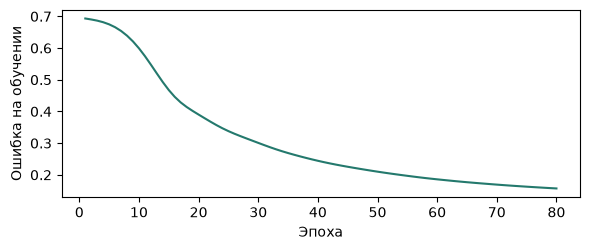

In [3]:
def encode(frame):
    return torch.tensor([(eid[h], rid[r], eid[t])
                         for h, r, t in frame[columns].itertuples(index=False, name=None)])

# targets[h, r, t] говорит, записан ли факт (h, r, t) в обучающей части.
targets = torch.zeros(len(entities), len(relations), len(entities), dtype=torch.bool)
h_train, r_train, t_train = encode(train).T
targets[h_train, r_train, t_train] = True
heads, rels = targets.any(dim=2).nonzero(as_tuple=True)
labels = targets[heads, rels].float()

class DistMult(nn.Module):
    def __init__(self, dim=32):
        super().__init__()
        self.entity = nn.Embedding(len(entities), dim)
        self.relation = nn.Embedding(len(relations), dim)
        nn.init.xavier_uniform_(self.entity.weight)
        nn.init.xavier_uniform_(self.relation.weight)

    def forward(self, heads, rels):
        # Одна строка на запрос, один столбец на страну-кандидата.
        query_vectors = self.entity(heads) * self.relation(rels)
        return query_vectors @ self.entity.weight.T

model = DistMult()
# Сохраним баллы до обучения, чтобы сравнить одну и ту же модель в двух состояниях.
with torch.no_grad():
    before = model(torch.arange(len(entities))[:, None], torch.arange(len(relations))).clone()
optimizer = torch.optim.Adam(model.parameters(), lr=0.03)
loss_history = []
for epoch in range(80):
    scores = model(heads, rels)
    loss = nn.functional.binary_cross_entropy_with_logits(scores, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())

with torch.no_grad():
    after = model(torch.arange(len(entities))[:, None], torch.arange(len(relations))).clone()
plt.figure(figsize=(6, 2.6))
plt.plot(range(1, 81), loss_history, color='#24796d')
plt.xlabel('Эпоха')
plt.ylabel('Ошибка на обучении')
plt.tight_layout()
plt.show()

## 3. Какое новое ребро проверить первым?

Модель выставит баллы всем 14 странам. Мы уже знаем четыре ответа из обучения, поэтому для **поиска новых фактов** уберём эти четыре страны. Оставшиеся десять отсортируем по баллу. Первые две строки — предложения модели для проверки. До этого момента мы использовали только обучающую часть.

In [4]:
h, r = eid[head], rid[relation]
candidates = pd.DataFrame({'страна': entities, 'балл': after[h, r].tolist()})
suggestions = candidates[~candidates['страна'].isin(known_tails)].sort_values('балл', ascending=False)
print('Два первых кандидата после исключения известных рёбер:')
display(suggestions.head(2).round(3).reset_index(drop=True))
for tail in suggestions['страна'].head(2):
    print(f'Предсказанный факт: ({head}, {relation}, {tail})')

Два первых кандидата после исключения известных рёбер:


,страна,балл
0,uk,0.832
1,egypt,0.160


Предсказанный факт: (china, embassy, uk)
Предсказанный факт: (china, embassy, egypt)


## 4. Подтверждаются ли предложения? Зачем ещё одна фильтрация?

Теперь откроем два отложенных файла. Сначала проверим по ним оба прогноза. Затем разберём **один** тестовый факт `(china, embassy, egypt)`. Здесь вопрос другой: какое место модель дала Египту среди стран, которые могли бы оказаться ошибочным ответом?

Если выше Египта оказалась страна, для которой эта же связь тоже записана, модель назвала другой верный ответ. При подсчёте места Египта в протоколе **filtered** эту страну пропускают. Сам Египет остаётся. Один и тот же набор баллов можно так проверить отдельно для каждого скрытого факта.

In [5]:
held_out = {s: pd.read_csv(read_table(s), sep='\t', names=columns) for s in ('valid', 'test')}
source = {}
for split, frame in {'train': train, **held_out}.items():
    tails = frame.loc[(frame['head'] == head) & (frame['relation'] == relation), 'tail']
    source.update({name: split for name in tails})

for tail in suggestions['страна'].head(2):
    print(f'({head}, {relation}, {tail}) — {source.get(tail, "в Nations подтверждения нет")}')
target = 'egypt'
assert source[target] == 'test'
candidates['запись в Nations'] = candidates['страна'].map(source).fillna('—')
candidates['место до обучения'] = pd.Series(before[h, r].tolist()).rank(ascending=False)
candidates['место после обучения'] = candidates['балл'].rank(ascending=False)
other_answers = candidates['страна'].isin(set(source) - {target})
candidates['место с фильтром'] = candidates['балл'].mask(other_answers).rank(ascending=False)
ordered = candidates.sort_values('балл', ascending=False)
display(ordered.round(3).set_index('страна').fillna('—'))
row = candidates[candidates['страна'] == target].iloc[0]
above = ordered[other_answers.reindex(ordered.index) & (ordered['балл'] > row['балл'])]
print(f'Египет среди всех стран: до обучения {row["место до обучения"]:g}-е место, '
      f'после {row["место после обучения"]:g}-е.')
print('Другие подтверждённые ответы выше Египта:', ', '.join(above['страна']))
print(f'Ранг Египта с фильтром: {row["место после обучения"]:g} − {len(above)} '
      f'= {row["место с фильтром"]:g}. Балл остался {row["балл"]:.3f}.')

(china, embassy, uk) — valid
(china, embassy, egypt) — test


,балл,запись в Nations,место до обучения,место после обучения,место с фильтром
страна,,,,,
ussr,2.083,train,11.0,1.0,—
poland,1.653,train,5.0,2.0,—
india,1.224,train,12.0,3.0,—
netherlands,1.210,train,8.0,4.0,—
uk,0.832,valid,2.0,5.0,—
egypt,0.160,test,9.0,6.0,1.0
cuba,-0.307,valid,10.0,7.0,—
indonesia,-0.479,test,7.0,8.0,—
brazil,-1.956,—,1.0,9.0,2.0


Египет среди всех стран: до обучения 9-е место, после 6-е.
Другие подтверждённые ответы выше Египта: ussr, poland, india, netherlands, uk
Ранг Египта с фильтром: 6 − 5 = 1. Балл остался 0.160.


Обратите внимание на подсказку внутри графа: в обучении есть обратная запись `(egypt, embassy, china)`. У DistMult перестановка двух стран сохраняет произведение координат и балл, поэтому модель может воспользоваться обратной связью. Для направленных отношений это ограничение.

## 5. Получилось ли восстановить и другие скрытые факты?

Одна удачная догадка мало говорит о качестве. По очереди скроем последнюю страну в **каждой** тестовой тройке и посчитаем её место по тому же правилу. **Hits@3** — доля тестовых фактов, в которых нужная страна вошла в первую тройку после фильтрации. Сравним результаты до обучения и после него. При равных баллах используем среднее занятых мест.

In [6]:
assert ('egypt', 'embassy', 'china') in set(train.itertuples(index=False, name=None))
# Эта маска нужна только для оценки. Баллы уже получены обученной моделью.
all_known = targets.clone()
for frame in held_out.values():
    h_eval, r_eval, t_eval = encode(frame).T
    all_known[h_eval, r_eval, t_eval] = True

h_test, r_test, t_test = encode(held_out['test']).T
sample = torch.arange(len(t_test))
other_known = all_known[h_test, r_test].clone()
other_known[sample, t_test] = False

def filtered_ranks(all_scores):
    scores = all_scores[h_test, r_test].masked_fill(other_known, -torch.inf)
    answer = scores[sample, t_test, None]
    ahead = (scores > answer).sum(dim=1)
    tied_others = (scores == answer).sum(dim=1) - 1
    return 1 + ahead + tied_others / 2

summary = []
for label, values in [('До обучения', before), ('После обучения', after)]:
    ranks = filtered_ranks(values)
    hits = int((ranks <= 3).sum())
    summary.append([label, hits, len(ranks), hits / len(ranks)])
result = pd.DataFrame(summary, columns=['Модель', 'Ответ в топ-3', 'Всего фактов', 'Hits@3'])
display(result.round(3))
print(f'После обучения в первую тройку попали ответы для {summary[1][1]} из '
      f'{len(ranks)} скрытых фактов. До обучения таких было {summary[0][1]}.')

,Модель,Ответ в топ-3,Всего фактов,Hits@3
0,До обучения,90,201,0.448
1,После обучения,172,201,0.856


После обучения в первую тройку попали ответы для 172 из 201 скрытых фактов. До обучения таких было 90.


### Проверьте себя

1. Какой факт предложила бы модель первым, если пополнять граф по данным обучения? В каком отложенном файле удалось его подтвердить?
2. Сколько стран оказалось выше Египта до применения оценочного фильтра? Что известно об их связях с Китаем?
3. Почему качество по всему тесту может быть ниже 100%, даже если для Египта ранг после фильтрации равен 1?

[Данные Nations](https://github.com/pykeen/pykeen/tree/2e3944f857a2f8e48c4f18d55649044a7e0f318d/src/pykeen/datasets/nations) · [Архивная практика: обучение TransE на FB15k-237](https://github.com/rustam-azimov/gnn-course-itmo/blob/main/archive/practice/practice07_kge.ipynb)